<a href="https://colab.research.google.com/github/baha-douma/portfolio/blob/main/TP2_Classification_binaire_Diabetes_modifi%C3%A9_ipynb_json.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#TP2 : Apprentissage supervisé, classification avec Python

Comment utiliser ce notebook
Google Colab : Fichier → Importer un notebook, puis Exécution → Tout exécuter. Toutes les bibliothèques nécessaires y sont déjà installées.
Rappel : de quoi parle ce TP ?
Apprentissage supervisé : on dispose d'exemples avec la bonne réponse. Le modèle apprend la relation entre les caractéristiques (features, notées X) et la cible (target, notée y), pour ensuite prédire y sur de nouveaux exemples.
Classification : la cible est une catégorie
Démarche standard : explorer les données → séparer apprentissage/test → entraîner → prédire → évaluer.

#  Importation des bibliothèques:

Ce code importe des bibliothèques essentielles pour le traitement l'analyse et la visualisation des données en Python :

**numpy :** Utilisé pour les calculs numériques et la manipulation des tableaux.

**matplotlib.pyplot :** Utilisé pour créer des graphiques et des visualisations.

**pandas :** Utilisé pour la manipulation et l'analyse des données structurées.

**seaborn :** Utilisé pour créer des visualisations statistiques attrayantes et informatives.

In [2]:
import numpy
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# importation du dataSet

Nous nous intéressons dans cet atelier à prédire si un patient est diabétique ou non, à partir de plusieurs informations médicales.

In [8]:
df=pd.read_csv("/content/sample_data/diabetes.csv")

In [ ]:
df

Afficher quelques lignes du datset

In [9]:
df.tail(13)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
755,1,128,88,39,110,36.5,1.057,37,1
756,7,137,90,41,0,32.0,0.391,39,0
757,0,123,72,0,0,36.3,0.258,52,1
758,1,106,76,0,0,37.5,0.197,26,0
759,6,190,92,0,0,35.5,0.278,66,1
760,2,88,58,26,16,28.4,0.766,22,0
761,9,170,74,31,0,44.0,0.403,43,1
762,9,89,62,0,0,22.5,0.142,33,0
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0


In [10]:
df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [11]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [12]:
df.shape


(768, 9)

In [13]:
df=df.dropna()
print ("Toutes les valeurs nulles ont été supprimées!")

Toutes les valeurs nulles ont été supprimées!


In [14]:
df.shape
#print("la dimension du dataset",D )

(768, 9)

### **Que remarquez vous?**

Fournir des statistiques descriptives pour les colonnes d'un DataFrame, telles que le nombre de valeurs non manquantes, la moyenne , l'écart-type, les valeurs minimales et maximales, ainsi que les quartiles.

In [15]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**Obtenir le nombre de patients avec et sans diabète (Outcome = 0 ou 1)**

In [16]:
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


Créer un histogramme des valeurs de la colonne 'Outcome' du DataFrame df, permettant de visualiser la distribution des deux classes (absence ou présence de diabète selon la cible du dataset).

plt.hist() : permet de tracer un histogramme pour visualiser la distribution des valeurs.
df['Outcome'] : sélectionne la colonne Outcome du DataFrame df.
bins=[-0.5, 0.5, 1.5] : définit les limites des intervalles de l'histogramme.
edgecolor='black' : ajoute une bordure noire aux barres pour mieux les distinguer.

Le premier intervalle va de -0,5 à 0,5 : il regroupe la valeur 0.

Le deuxième intervalle va de 0,5 à 1,5 : il regroupe la valeur 1.
Nous avons choisi ces limites manuellement pour obtenir exactement deux barres, une pour chaque classe.

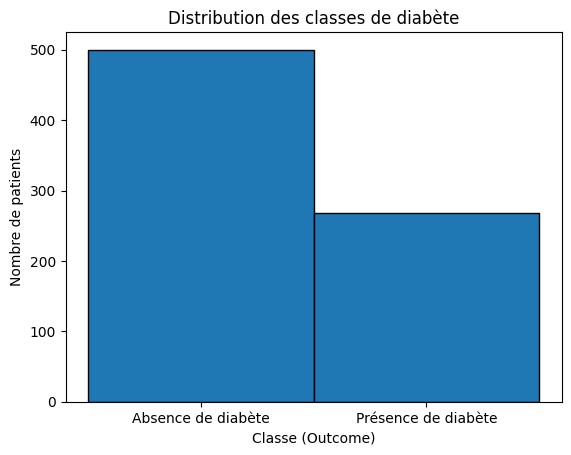

In [17]:
plt.hist(df['Outcome'], bins=[-0.5, 0.5, 1.5], edgecolor='black')
plt.xticks([0, 1], ['Absence de diabète', 'Présence de diabète'])#permet de remplacer les nombres 0 et 1 par des étiquettes plus faciles à comprendre.
plt.xlabel('Classe (Outcome)')
plt.ylabel('Nombre de patients')
plt.title('Distribution des classes de diabète')
plt.show()

Créer une matrice de graphiques de dispersion à partir des colonnes Glucose, BloodPressure et SkinThickness du DataFrame df, en utilisant la colonne Outcome pour différencier les classes par couleur.

L'objectif  est de visualiser les relations entre trois caractéristiques des patients et de voir si elles permettent de distinguer les patients avec et sans diabète.

C'est une étape importante de l'analyse exploratoire des données (Exploratory Data Analysis — EDA) avant d'entraîner un modèle de Machine Learning.

- sns est l'abréviation habituelle de la bibliothèque Seaborn, utilisée pour créer des graphiques statistiques.
- pairplot() permet de créer une matrice de graphiques : plusieurs graphiques organisés dans une même figure.
- Elle permet d'étudier les distributions des variables et les relations entre elles.
Au lieu de créer trois ou plusieurs graphiques manuellement, cette fonction les génère automatiquement.

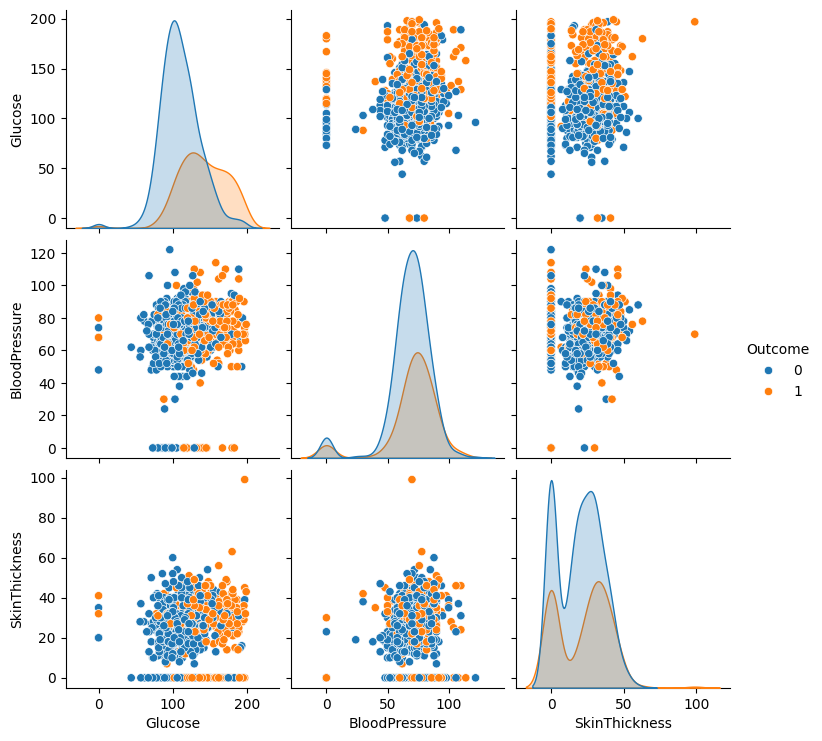

In [18]:


sns.pairplot(
    df,
    vars=['Glucose', 'BloodPressure', 'SkinThickness'],
    hue='Outcome'
)

plt.show()

Afficher les valeurs distinctes pour une  colonne quelconque





Cela permet de comprendre les données avant de construire un modèle.

In [19]:
print(df['Outcome'].unique())


[1 0]


envoie la liste des valeurs différentes présentes dans la colonne Outcome, sans doublons.

Sur votre dataset (768 lignes), au lieu de voir 768 valeurs répétées (0, 1, 0, 0, 1...), vous obtenez seulement :

[1 0]

In [20]:
print(df['Glucose'].unique())


[148  85 183  89 137 116  78 115 197 125 110 168 139 189 166 100 118 107
 103 126  99 196 119 143 147  97 145 117 109 158  88  92 122 138 102  90
 111 180 133 106 171 159 146  71 105 101 176 150  73 187  84  44 141 114
  95 129  79   0  62 131 112 113  74  83 136  80 123  81 134 142 144  93
 163 151  96 155  76 160 124 162 132 120 173 170 128 108 154  57 156 153
 188 152 104  87  75 179 130 194 181 135 184 140 177 164  91 165  86 193
 191 161 167  77 182 157 178  61  98 127  82  72 172  94 175 195  68 186
 198 121  67 174 199  56 169 149  65 190]


# Transformation des données

La variable cible 'Outcome' est déjà codée en binaire : 0 représente l'absence de diabète et 1 la présence de diabète selon le dataset. Vérifier les valeurs de cette colonne.

In [21]:
df['Outcome'] = df['Outcome'].astype(int)


Vérifier les changements

In [22]:
print("Les valeurs de la colonne Outcome sont :", df["Outcome"].unique())

Les valeurs de la colonne Outcome sont : [1 0]



# Feature Extraction : critères de sélection des colonnes

Lors de la préparation d'un dataset, certaines colonnes peuvent être retirées lorsqu'elles n'apportent pas d'informations utiles à l'apprentissage du modèle. Plusieurs critères peuvent guider cette sélection.

**1) Identifiants et variables peu utiles :**

Éliminer les colonnes qui ne contribuent pas aux prédictions, notamment les identifiants uniques qui ne fournissent aucune information pertinente au modèle.

**2) Faible variance :**

Retirer les variables dont les valeurs changent très peu d'une observation à une autre, car elles apportent généralement peu d'informations.

**3) Corrélation élevée et redondance :**

Identifier les colonnes qui présentent une forte corrélation entre elles et envisager d'en supprimer certaines afin de limiter la multicolinéarité et la répétition d'informations.

**4) Manque de pertinence :**

Exclure les variables qui n'ont pas de lien utile avec l'objectif de l'analyse ou avec la variable que l'on souhaite prédire.

**5) Données incorrectes ou mal structurées :**

Envisager de supprimer les colonnes qui contiennent des données incohérentes ou mal formatées lorsqu'il est difficile de les corriger ou de les exploiter correctement.

**6) Textes longs non transformés :**

Supprimer ou prétraiter les colonnes contenant de longs textes lorsque ceux-ci n'ont pas encore été convertis en une représentation exploitable par les algorithmes de Machine Learning.

**7) Nombre important de valeurs manquantes :**

Supprimer les colonnes présentant une proportion élevée de données absentes, par exemple supérieure à 50 %, lorsque leur récupération ou leur imputation n'est pas pertinente.

# **1) suppression des données inutiles**

In [23]:
# Le dataset Diabetes ne contient pas de colonne identifiant inutile à supprimer.
# Si vous identifiez une colonne non pertinente, supprimez-la ici.
# Exemple de syntaxe :df=df.drop(columns=['nom_colonne'])


In [24]:
print ("les autres colonnes", df.columns)

les autres colonnes Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


# La corrélation

L'analyse de la corrélation entre les différentes colonnes d'un dataset permet d'étudier les relations linéaires qui existent entre les variables. Elle présente plusieurs intérêts lors de l'analyse et de la préparation des données.

**1) Explorer et comprendre les données :**

L'étude des corrélations permet d'avoir une vue d'ensemble des relations entre les variables et de mieux comprendre la structure du dataset dès les premières étapes de l'analyse exploratoire.

**2) Identifier les relations entre les variables :**

La corrélation permet de repérer si deux variables évoluent dans le même sens (corrélation positive) ou dans des sens opposés (corrélation négative).

**3) Repérer les anomalies éventuelles :**

Des corrélations inhabituelles peuvent signaler des valeurs suspectes, des erreurs de saisie ou des incohérences dans les données, qu'il convient d'examiner davantage.

**4) Limiter les informations redondantes :**

Lorsque deux variables présentent une forte corrélation, elles peuvent apporter des informations similaires. Supprimer l'une d'elles ou les combiner peut alors réduire la redondance et simplifier certains modèles.

**5) Contribuer à la sélection des variables prédictives :**

L'analyse des corrélations peut aider à repérer les variables potentiellement utiles pour effectuer des prédictions. Une forte corrélation entre une variable explicative et la variable cible peut être intéressante, mais elle ne garantit pas à elle seule que cette variable sera un bon prédicteur.

- Corrélation positive : quand une variable augmente, l'autre a tendance à augmenter aussi.
- Corrélation négative : quand une variable augmente, l'autre a tendance à diminuer.
- Corrélation proche de zéro : il n'y a pas de relation linéaire claire entre les deux variables.
Le coefficient de corrélation est compris entre -1 et +1.

**1) Calculer la matrice de corrélation**

df : notre tableau de données contenant les patients.

.corr() : calcule les coefficients de corrélation entre les colonnes numériques.

numeric_only=True : ne prend en compte que les colonnes numériques.

c = : stocke le résultat dans une variable appelée c.

In [25]:
c = df.corr(numeric_only=True)

**2) visualiser la matrice de correlation correlation**

- figsize=(10, 8) : définit sa taille, avec une largeur de 10 pouces et une hauteur de 8 pouces.

Cette ligne crée la représentation visuelle de la matrice de corrélation.
- sns.heatmap(...) : affiche les coefficients sous forme de cases colorées.
- df.corr(numeric_only=True) : calcule la matrice des corrélations à afficher.
- annot=True : affiche la valeur numérique dans chaque case.
- fmt=".2f" : affiche chaque valeur avec deux chiffres après la virgule, par exemple 0.75 ou -0.32.

<Axes: >

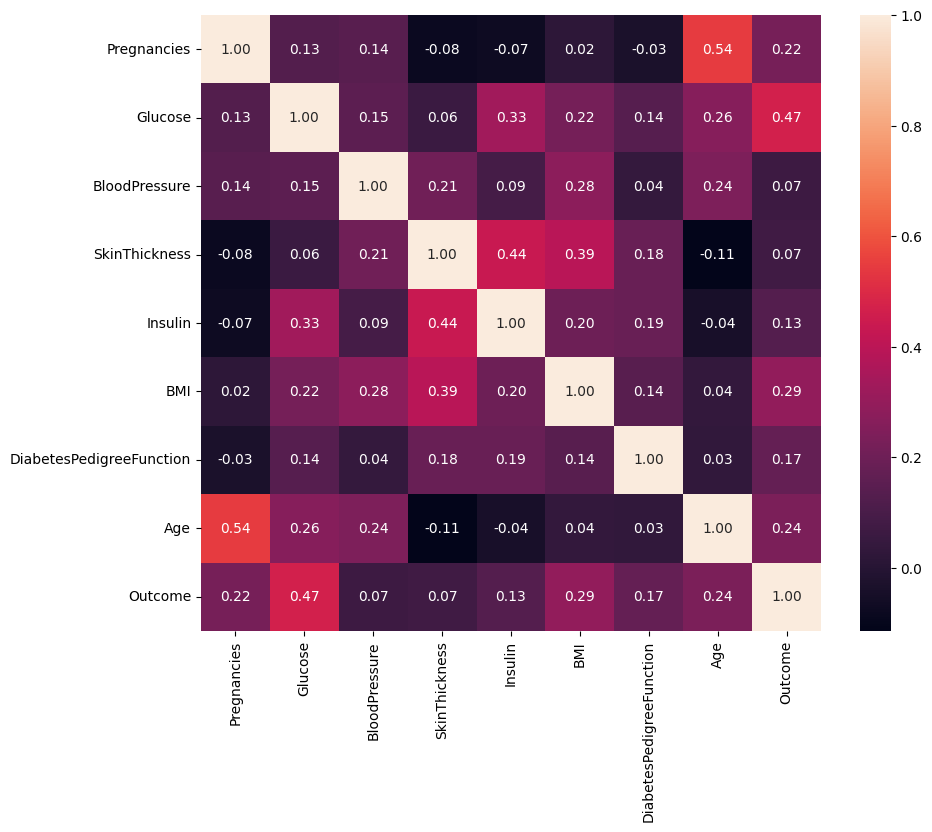

In [26]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f")

Proche de +1 : relation positive forte.

Proche de 0 : relation linéaire faible ou nulle.

Proche de -1 : relation négative forte.
Glucose et Outcome ont une corrélation de 0.47 : une relation positive modérée.

BloodPressure et Outcome ont une corrélation de 0.07 : une relation linéaire très faible.

- La diagonale contient des 1.00, car chaque variable est parfaitement corrélée avec elle-même.

# Répartition des données (X et Y)

df : le DataFrame qui contient les données des patients.

.drop(columns=['Outcome']) : supprime la colonne Outcome du tableau.

X : contient les 8 variables explicatives (features) utilisées pour prédire le diabète.

X représente les informations que nous donnons au modèle : glucose, âge, pression artérielle, etc.

Y représente la réponse attendue : absence ou présence de diabète.

In [27]:
X=df.drop(columns=['Outcome'])
Y=df['Outcome']

In [28]:
print("Dimensions de X :", X.shape)
print("Dimensions de y :", Y.shape)

Dimensions de X : (768, 8)
Dimensions de y : (768,)


# Normalisation des données (les X)

La normalisation et la standardisation sont des étapes cruciales pour améliorer la convergence
des algorithmes d’apprentissage. - -
La Normalisation :(par exemple, MinMaxScaler de scikit-learn) ajuste les données de
sorte qu'elles aient une échelle commune, souvent entre 0 et 1. Cela est utile quand les
variables d'entrée ont des échelles différentes.
La Standardisation : (par exemple, StandardScaler de scikit-learn) transforme les
données de manière à ce qu'elles aient une moyenne de 0 et un écart-type de 1. Elle est
particulièrement utile pour les modèles qui supposent que les données suivent une
distribution normale.

« Nos variables ont des échelles différentes. StandardScaler les transforme pour qu'elles aient une moyenne proche de zéro et un écart-type proche de un. Ainsi, les algorithmes sensibles aux échelles peuvent apprendre plus efficacement. La standardisation ne supprime aucune colonne : elle modifie seulement les valeurs numériques. »

La normalisation (MinMaxScaler)
Définition :

La normalisation transforme les valeurs d'une variable pour les ramener généralement dans un intervalle compris entre 0 et 1.

La standardisation (StandardScaler)
Définition :

La standardisation transforme les valeurs pour obtenir :
- Une moyenne égale à 0.
- Un écart-type égal à 1.
Attention : contrairement à la normalisation, les valeurs standardisées ne sont pas obligatoirement comprises entre 0 et 1.

In [29]:
from sklearn.preprocessing import StandardScaler
X=StandardScaler().fit_transform(X)

#Répartition des données entre train et test

Il s’agit de séparer les attributs et les classes puis répartir le jeu de données en deux parties. Les
données sont divisées en jeu d’apprentissage (training set) et jeu de test (test set). Cela permet
d’entraîner le modèle sur une partie des données et d’évaluer sa performance sur des données
inédites.

sklearn.model_selection : module de Scikit-learn qui contient des outils pour préparer et évaluer les modèles.

train_test_split : fonction qui divise les données en plusieurs ensembles.

test_size=0.20

Réserve 20 % des données pour le test et 80 % pour l'entraînement.


random_state=0

Fixe la graine aléatoire pour obtenir la même division lors des exécutions successives, si les données restent identiques.

X_train : les caractéristiques des patients utilisées pour entraîner le modèle.

Y_train : les réponses correctes associées à ces patients.

X_test : les caractéristiques des patients réservés au test.

Y_test : les réponses correctes permettant de comparer les prédictions aux résultats réels.

« Le paramètre stratify=Y permet de conserver la même répartition des classes dans les données d'entraînement et de test. C'est particulièrement important lorsqu'on travaille avec un problème de classification, surtout si les classes ne sont pas équilibrées. »

Maintient approximativement la même proportion de patients des classes 0 et 1 dans les ensembles d'entraînement et de test que dans le dataset initial.

In [30]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.20,random_state=0,stratify=Y)

# Implémentation des modèles IA

***syntaxe d'implémentation:***

from bibliothèque import algorithme

nomModèle= algorithme(paramètres d'implémentation)

nomModèle.fit(Données de train, les bonnes réponses correspondantes)


***pour l'évaluation***
from bibliothèque import fonction

fonction (données de test, les bonnes réponses correspondantes)

**1. La Régression Logistique:**


La régression logistique est une méthode de classification qui permet d'estimer la probabilité qu'un individu appartienne à une classe particulière. À la différence de la régression linéaire, qui prédit une valeur numérique continue, elle utilise la fonction sigmoïde pour transformer le résultat en une probabilité comprise entre 0 et 1.

LogisticRegression() crée un modèle de régression logistique.

log est le nom de la variable dans laquelle on stocke le modèle.

max_iter=1000 autorise l'algorithme à effectuer jusqu'à 1 000 itérations pour trouver les paramètres du modèle.

In [31]:
# Logistic regression
from sklearn.linear_model import LogisticRegression #importer l'algorithme
log=LogisticRegression(max_iter=1000)
log.fit(X_train,Y_train)

LogisticRegression(max_iter=1000)

## 2. L'arbre de décision

L'arbre de décision est un algorithme de Machine Learning qui peut être utilisé aussi bien pour la classification que pour la régression. Il organise les données sous forme d'arbre et les divise progressivement selon différentes conditions afin d'obtenir des groupes plus homogènes.

**a) Construction de l'arbre :**

À chaque étape, l'algorithme choisit la variable et le seuil de séparation les plus adaptés pour répartir les données. En classification, cette sélection peut se baser sur l'indice de Gini ou l'entropie, tandis qu'en régression, elle peut s'appuyer sur la réduction de la variance. Le processus se poursuit jusqu'à ce qu'une condition d'arrêt soit satisfaite, par exemple une profondeur maximale de l'arbre ou un nombre minimal d'observations dans une feuille.

**b) Étape de prédiction :**

Pour effectuer une prédiction, une nouvelle observation traverse les différents nœuds en suivant les conditions définies dans l'arbre jusqu'à atteindre une feuille terminale. Cette feuille fournit alors la classe prédite dans le cas d'une classification, ou une valeur numérique dans le cas d'une régression.

Cet algorithme présente l'avantage d'être facile à comprendre et à interpréter. Il peut traiter des variables numériques ainsi que des variables catégorielles après un encodage approprié si nécessaire. Toutefois, un arbre trop complexe risque de surapprendre les données d'entraînement (*overfitting*). Des méthodes comme l'élagage ou les forêts aléatoires permettent de limiter ce problème et d'améliorer la robustesse des prédictions.

tree : variable qui contient notre modèle.
tree.fit(X_train, Y_train): Le modèle apprend à partir des caractéristiques et des classes connues pour construire son arbre de décision.

DecisionTreeClassifier() : crée un arbre de décision.

random_state=0 : permet de fixer l'aléatoire pour obtenir les mêmes résultats lors des exécutions, dans les mêmes conditions.

#Chargement de l’algorithme et lancement de l’apprentissage

In [35]:
# Decision Tree
from sklearn.tree import DecisionTreeClassifier
tree=DecisionTreeClassifier(random_state=0)
tree.fit(X_train,Y_train)

DecisionTreeClassifier(random_state=0)

# Evaluation des modèles

l’accuracy (le taux de bonnes prédictions)
L'accuracy représente le pourcentage de prédictions correctes.

Accurarcy= TP+TN/TP+TN+FP+FN

TP (True Positive) : le patient est diabétique et le modèle prédit qu'il l'est.



TN (True Negative) : le patient n'est pas diabétique et le modèle prédit qu'il ne l'est pas.



FP (False Positive) : le patient n'est pas diabétique, mais le modèle prédit qu'il l'est.



FN (False Negative) : le patient est diabétique, mais le modèle prédit qu'il ne l'est pas.

In [36]:
print('Decision tree accuracy:',tree.score(X_test,Y_test))


Decision tree accuracy: 0.7012987012987013


Interprétation de l'accuracy initiale
Résultat obtenu
70,13 %
Cela signifie que le modèle a correctement classé environ 70,13 % des observations du jeu de test.

les 29,87 % restants correspondent aux prédictions incorrectes.

#Optimisation des hyper paramètres :
Les hyperparamètres dans les algorithmes d'apprentissage automatique sont des paramètres
ajustables avant le processus d'entraînement. Leur importance réside dans leur capacité à
influencer la performance et la généralisation du modèle.
Des choix judicieux d'hyperparamètres sont cruciaux pour éviter le surajustement ou le sous
ajustement du modèle.  
Ces ajustements impactent des aspects tels que la complexité du modèle, sa capacité à généraliser
et sa robustesse. Une exploration méticuleuse de l'espace des hyperparamètres est essentielle
pour maximiser la performance du modèle, et leur réévaluation peut être nécessaire face à de
nouveaux ensembles de données ou conditions d'application.
Si on ne connait pas exactement les hyperparamètres d’un algorithme quelconque, nous pouvons
utiliser la fonction get_params () définie dans la bibliothèque scikit-learn.

In [37]:
hyperparameters = tree.get_params()

# Afficher les hyperparamètres
print("Hyperparamètres du DecisionTreeClassifier :")

for param, value in hyperparameters.items():
    print(param, ':', value)

Hyperparamètres du DecisionTreeClassifier :
ccp_alpha : 0.0
class_weight : None
criterion : gini
max_depth : None
max_features : None
max_leaf_nodes : None
min_impurity_decrease : 0.0
min_samples_leaf : 1
min_samples_split : 2
min_weight_fraction_leaf : 0.0
monotonic_cst : None
random_state : 0
splitter : best


La méthode get_params() permet de récupérer tous les paramètres du modèle.
remarque importante : None ne signifie pas zéro. Par exemple, max_depth=None signifie qu'on ne fixe pas de profondeur maximale à l'arbre.

#L'objectif est de tester différentes valeurs des hyperparamètres pour voir si on peut améliorer les performances de notre arbre de décision.

Ce code permet de tester plusieurs configurations d’un arbre de décision et de comparer leurs performances. On cherche à voir comment les paramètres de l’arbre influencent son accuracy.

In [38]:

from sklearn.tree import DecisionTreeClassifier

# Modèle initial
tree1 = DecisionTreeClassifier(random_state=0)
tree1.fit(X_train, Y_train)
print("Accuracy initiale :", tree1.score(X_test, Y_test))

# Test 1 : limiter la profondeur
tree2 = DecisionTreeClassifier(max_depth=3, random_state=0) #max_depth=3 signifie que la profondeur maximale de l’arbre est limitée à 3 niveaux de décisions.
tree2.fit(X_train, Y_train)
print("Accuracy max_depth=3 :", tree2.score(X_test, Y_test))

# Test 2 : augmenter le nombre minimum pour diviser un noeud
tree3 = DecisionTreeClassifier(min_samples_split=10, random_state=0) #signifie qu’un nœud doit contenir au moins 10 observations pour pouvoir être divisé en plusieurs sous-nœuds.
tree3.fit(X_train, Y_train)
print("Accuracy min_samples_split=10 :", tree3.score(X_test, Y_test))

# Test 3 : augmenter le nombre minimum d'échantillons par feuille
tree4 = DecisionTreeClassifier(min_samples_leaf=5, random_state=0) #signifie que chaque feuille finale de l’arbre doit contenir au moins 5 observations d’entraînement.
tree4.fit(X_train, Y_train)
print("Accuracy min_samples_leaf=5 :", tree4.score(X_test, Y_test))


Accuracy initiale : 0.7012987012987013
Accuracy max_depth=3 : 0.7987012987012987
Accuracy min_samples_split=10 : 0.7272727272727273
Accuracy min_samples_leaf=5 : 0.6753246753246753


Important : les quatre modèles sont entraînés indépendamment sur les mêmes données d'entraînement. On ne modifie pas progressivement tree1.

Que signifie max_depth=3 ?

Cela signifie qu'on limite la profondeur maximale de l'arbre à 3.

Autrement dit, on empêche l'arbre de devenir trop complexe.

Pourquoi faire cela ?

Un arbre trop profond risque de mémoriser les données d'entraînement au lieu d'apprendre des règles générales. Ce phénomène s'appelle le surapprentissage (Overfitting).

En limitant sa profondeur, on essaie d'obtenir un modèle capable de mieux généraliser sur de nouvelles données.

#Interprétation1 :

L'accuracy passe de 70,13 % à 79,87 %.

Cela signifie que la limitation de la profondeur à 3 a amélioré les performances du modèle sur les données de test.

C'est une amélioration de 9,74 points de pourcentage.

#Interprétation2 :

L'accuracy passe de 70,13 % à 72,73 %.

Il y a donc une légère amélioration par rapport au modèle initial.

Cependant, ce résultat reste inférieur à celui obtenu avec max_depth=3 (79,87 %).

#Interprétation3 :

L'accuracy passe de 70,13 % à 67,53 %.

On constate une diminution des performances.

Cela signifie que cette contrainte, avec une valeur de 5, n'a pas amélioré les prédictions sur les données de test.

#Conclusion:
« Dans cette partie, nous allons essayer d'améliorer notre arbre de décision en modifiant certains hyperparamètres.

Premièrement, nous créons un modèle initial et nous calculons son accuracy. Nous obtenons 70,13 %.

Ensuite, nous testons trois hyperparamètres :
- max_depth pour limiter la profondeur de l'arbre.
- min_samples_split pour définir le nombre minimum d'observations nécessaires pour diviser un nœud.
- min_samples_leaf pour définir le nombre minimum d'observations dans une feuille.
Après chaque modification, nous entraînons un nouveau modèle et nous calculons son accuracy.

Enfin, nous comparons les résultats pour identifier la configuration qui donne la meilleure performance.

Dans notre cas, c'est le modèle avec max_depth=3 qui donne le meilleur résultat, avec une accuracy de 79,87 %. »

## 3. Random Forest (Forêt aléatoire)

Le Random Forest est un algorithme d'apprentissage automatique qui repose sur la combinaison de plusieurs arbres de décision. En regroupant leurs prédictions, il vise à obtenir des résultats plus fiables et à améliorer les performances du modèle.

**Principe de fonctionnement**

**a) Entraînement de plusieurs arbres de décision :**

L'algorithme construit plusieurs arbres à partir de différents échantillons aléatoires du jeu de données, généralement obtenus par la méthode *bootstrap*. De plus, lors de chaque division d'un nœud, un sous-ensemble aléatoire de variables est considéré afin de diversifier les arbres et de limiter leur dépendance les uns aux autres.

**b) Combinaison des prédictions :**

- **En classification :** chaque arbre propose une classe, et la classe finale est généralement choisie par vote majoritaire.
- **En régression :** le résultat final correspond à la moyenne des valeurs prédites par les différents arbres.

Grâce à la combinaison de plusieurs arbres, le Random Forest réduit généralement le risque de surapprentissage par rapport à un arbre de décision isolé et améliore la capacité du modèle à généraliser à de nouvelles données. Il est adapté à de nombreux problèmes, notamment lorsque les données sont complexes ou contiennent du bruit. Il reste relativement facile à utiliser, même si l'interprétation de l'ensemble du modèle est plus difficile que celle d'un arbre unique.

In [39]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
forest=RandomForestClassifier(random_state=0)
forest.fit(X_train,Y_train)

RandomForestClassifier(random_state=0)

## 4. K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) est un algorithme d'apprentissage supervisé qui peut être appliqué à des tâches de classification et de régression. Son fonctionnement repose sur la proximité entre les observations : les données qui se ressemblent ont tendance à se situer près les unes des autres dans l'espace des caractéristiques.

**Principe de fonctionnement**

**a) Calcul des distances :**

Lorsqu'une nouvelle observation est présentée, l'algorithme calcule sa distance par rapport aux observations du jeu de données d'entraînement. Plusieurs mesures peuvent être utilisées, comme la distance euclidienne ou la distance de Manhattan.

**b) Recherche des K plus proches voisins :**

Parmi les observations disponibles, KNN retient les \(K\) points les plus proches de la nouvelle donnée. Le paramètre \(K\) correspond donc au nombre de voisins pris en compte pour effectuer la prédiction.

**c) Détermination du résultat :**

- **En classification :** la classe attribuée à la nouvelle observation est généralement celle qui apparaît le plus souvent parmi les \(K\) voisins sélectionnés.
- **En régression :** la valeur prédite est généralement calculée à partir de la moyenne des valeurs des voisins retenus.

KNN est un algorithme facile à comprendre et à mettre en œuvre, particulièrement adapté à certains jeux de données de petite ou moyenne taille. Cependant, les prédictions peuvent devenir coûteuses en temps de calcul lorsque le nombre d'observations augmente. De plus, la mise à l'échelle des variables est souvent importante, car les distances sont sensibles aux différences d'échelle entre les caractéristiques.

In [40]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,Y_train)

KNeighborsClassifier()

In [41]:
print('Logistic regression accuracy:',log.score(X_test,Y_test))
print('Decision tree accuracy:',tree.score(X_test,Y_test))
print('Random forest accuracy:',forest.score(X_test,Y_test))
print('KNeighbors accuracy:',knn.score(X_test,Y_test))


Logistic regression accuracy: 0.7792207792207793
Decision tree accuracy: 0.7012987012987013
Random forest accuracy: 0.8116883116883117
KNeighbors accuracy: 0.7792207792207793


## Évaluation des modèles : matrice de confusion
La matrice de confusion (Confusion Matrix) est un outil en Machine Learning qui permet d'évaluer les performances d'un modèle de classification. Elle compare les prédictions du modèle avec les vraies réponses.

La matrice de confusion permet de comparer les classes réelles avec les classes prédites par le modèle. Elle permet d'identifier les bonnes prédictions et les erreurs de classification.

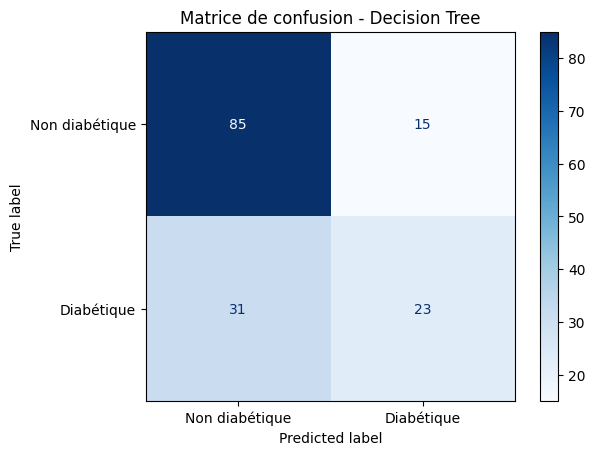

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Prédire les classes des patients du test
y_pred = tree.predict(X_test)

# Calculer la matrice de confusion
cm = confusion_matrix(Y_test, y_pred)

# Afficher la matrice
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non diabétique", "Diabétique"]
)

disp.plot(cmap="Blues")
plt.title("Matrice de confusion - Decision Tree")
plt.show()

- Les lignes (axe vertical) représentent les vraies classes (True label).
- Les colonnes (axe horizontal) représentent les classes prédites par le modèle (Predicted label).

vous pouvez ensuite reproduire cette cellule pour les autres modèles en remplaçant tree par log, forest ou knn.

### Évaluation du modèle : taux d'erreur, Recall, Precision et F1-score
L'objectif de ce code est d'aller plus loin que l'Accuracy et de comprendre plus précisément les erreurs et les bonnes prédictions de notre Decision Tree.

Ces métriques permettent d'évaluer les performances d'un modèle de classification :

- **Taux d'erreur** : proportion des prédictions incorrectes.
- **Recall (rappel)** : proportion des vrais positifs correctement détectés parmi tous les positifs réels.(TP/TP+FN)
- **Precision (précision)** : proportion des vrais positifs parmi les prédictions positives.
- **F1-score** : moyenne harmonique de la précision et du rappel.Il permet de trouver un équilibre entre les deux.
F1=2x (Precision x Recall/ Precision + Recall)

In [46]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Prédictions sur les données de test
y_pred = tree.predict(X_test)

# Calcul de la matrice de confusion
tn, fp, fn, tp = confusion_matrix(Y_test, y_pred).ravel()#ravel:Permet de transformer la matrice 2 × 2 en une seule séquence de quatre valeurs.

# Calcul des métriques
taux_erreur = (fp + fn) / (tp + tn + fp + fn)
recall = recall_score(Y_test, y_pred, zero_division=0)
precision = precision_score(Y_test, y_pred, zero_division=0)#zero_division=0 permet d'éviter une erreur ou un avertissement si le calcul d'une métrique nécessite une division par zéro.

#Dans ce cas, la fonction retourne 0.
f1 = f1_score(Y_test, y_pred, zero_division=0)

# Affichage des résultats
print("Taux d'erreur :", round(taux_erreur, 4))
print("Recall :", round(recall, 4))
print("Precision :", round(precision, 4))
print("F1-score :", round(f1, 4))

Taux d'erreur : 0.2987
Recall : 0.4259
Precision : 0.6053
F1-score : 0.5


Interprétation : notre modèle a commis des erreurs de classification sur environ 29,87 % des patients testés.

À retenir : plus le taux d'erreur est faible, mieux c'est.
Le F1-score est de 50 %.
Recall : 0.4259 ,À retenir : plus le Recall est élevé, plus le modèle arrive à détecter les patients réellement diabétiques.

Precision : 0.6053 : environ 60,53 % des patients prédits diabétiques le sont réellement.

À retenir : plus la Precision est élevée, plus les prédictions positives sont fiables.
F1-score : 0.5

Cela indique que l'équilibre entre la Precision et le Recall est relativement faible.

À retenir : plus le F1-score est élevé, meilleur est l'équilibre entre les deux métriques.